# Project 11 - Inventory Image Tagging
## Phase 1: pixels, HOG, and classical ML

We predict one of ten clothing categories from a 28x28 grayscale image. The notebook follows the saved Phase 1 experiment and checks its results. We will test CNNs in Phase 2.

**Run stages first:** `uv sync --locked`, then `uv run python3 -m src.inventory_tagging.cli prepare`, `eda`, `train`, `improve`, and `evaluate`. Evaluation freezes choices and refuses a second run. `improve` is a separate, explicitly labeled classical extension.

In [ ]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.inventory_tagging.data import CLASSES, load_images, split_indices
from src.inventory_tagging.features import extract
from src.inventory_tagging.models import build
print("Project:", ROOT.name)
print("Categories:", ", ".join(CLASSES))

Project: inventory-image-tagging
Categories: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


## 1. Dataset and split
The official dataset has 60,000 training images and 10,000 test images. Using seed 42, we divide the official training set into 48,000 training and 12,000 validation images, keeping class proportions equal. Every model uses the same training IDs. We choose settings using validation macro F1 and fix those choices before calculating test scores.

The public test benchmark was already used in the supplied reference. The results describe this public benchmark. Performance on new kinds of images still needs testing.

In [ ]:
audit = json.loads((ROOT / "reports/data_audit.json").read_text())
display(pd.Series(audit).drop("archives"))
display(pd.read_csv(ROOT / "reports/class_counts.csv"))
images, labels = load_images("train")
train_ids, validation_ids = split_indices(labels)
assert not np.intersect1d(train_ids, validation_ids).size
assert len(train_ids) == 48000


official_training_images                                                      60000
training_images                                                               48000
validation_images                                                             12000
image_shape                                                                [28, 28]
dtype                                                                         uint8
pixel_range                                                                [0, 255]
blank_images                                                                      0
exact_duplicate_images                                                            0
split_overlap                                                                     0
train_validation_image_overlap                                                    0
finite_pixels                                                                  True
near_duplicate_check              Not established by exact hashing; product 

,label,category,official_train,training,validation
0,0,T-shirt/top,6000,4800,1200
1,1,Trouser,6000,4800,1200
2,2,Pullover,6000,4800,1200
3,3,Dress,6000,4800,1200
4,4,Coat,6000,4800,1200
5,5,Sandal,6000,4800,1200
6,6,Shirt,6000,4800,1200
7,7,Sneaker,6000,4800,1200
8,8,Bag,6000,4800,1200
9,9,Ankle boot,6000,4800,1200


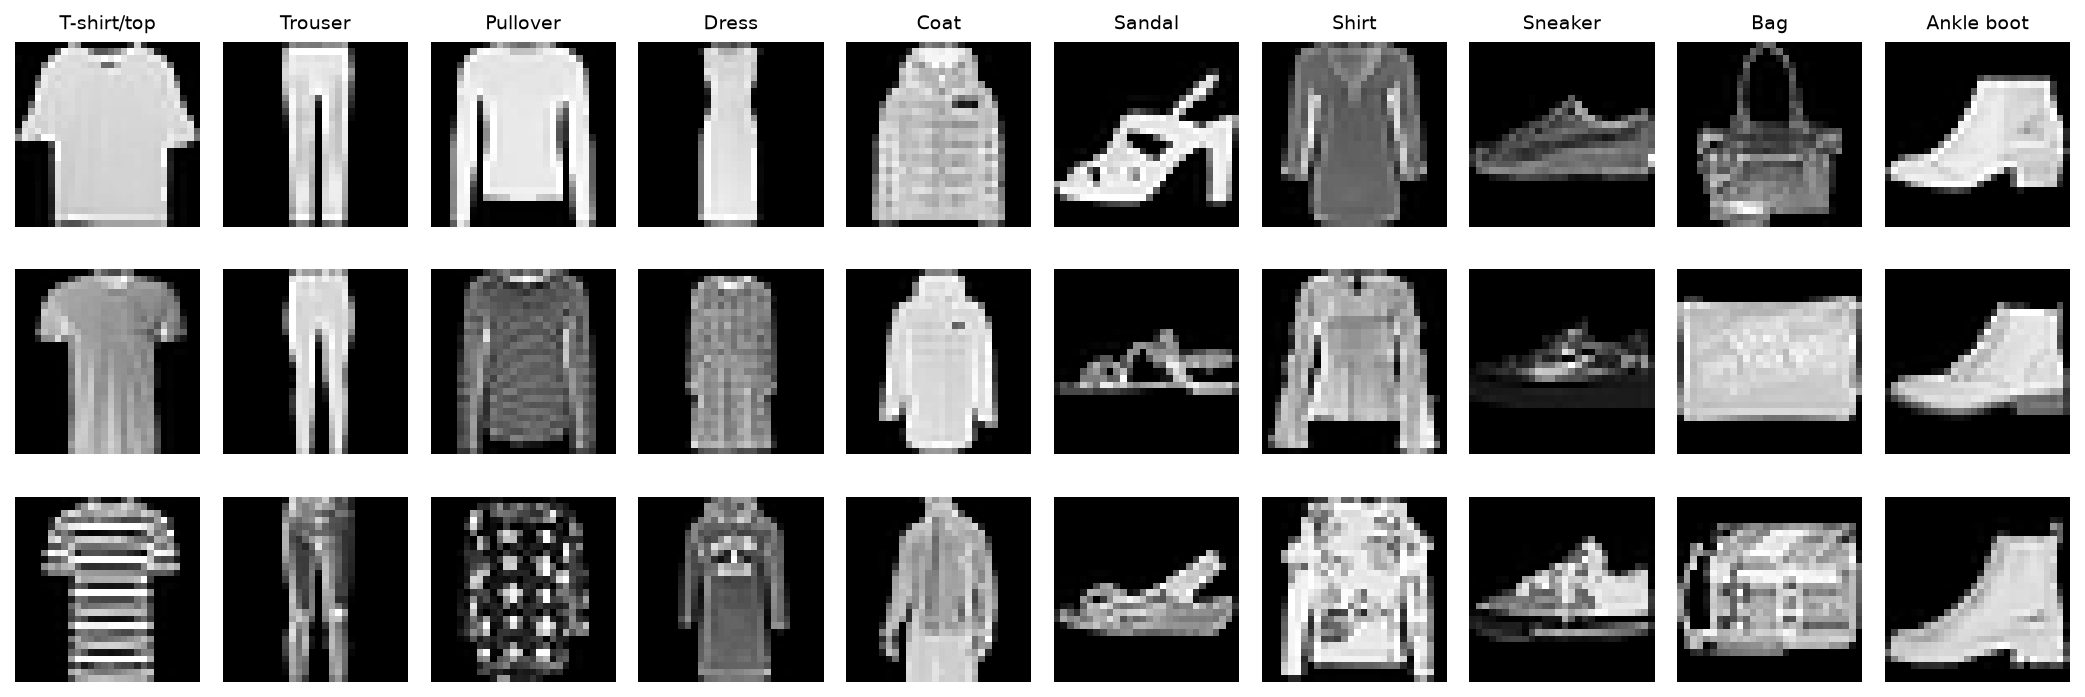

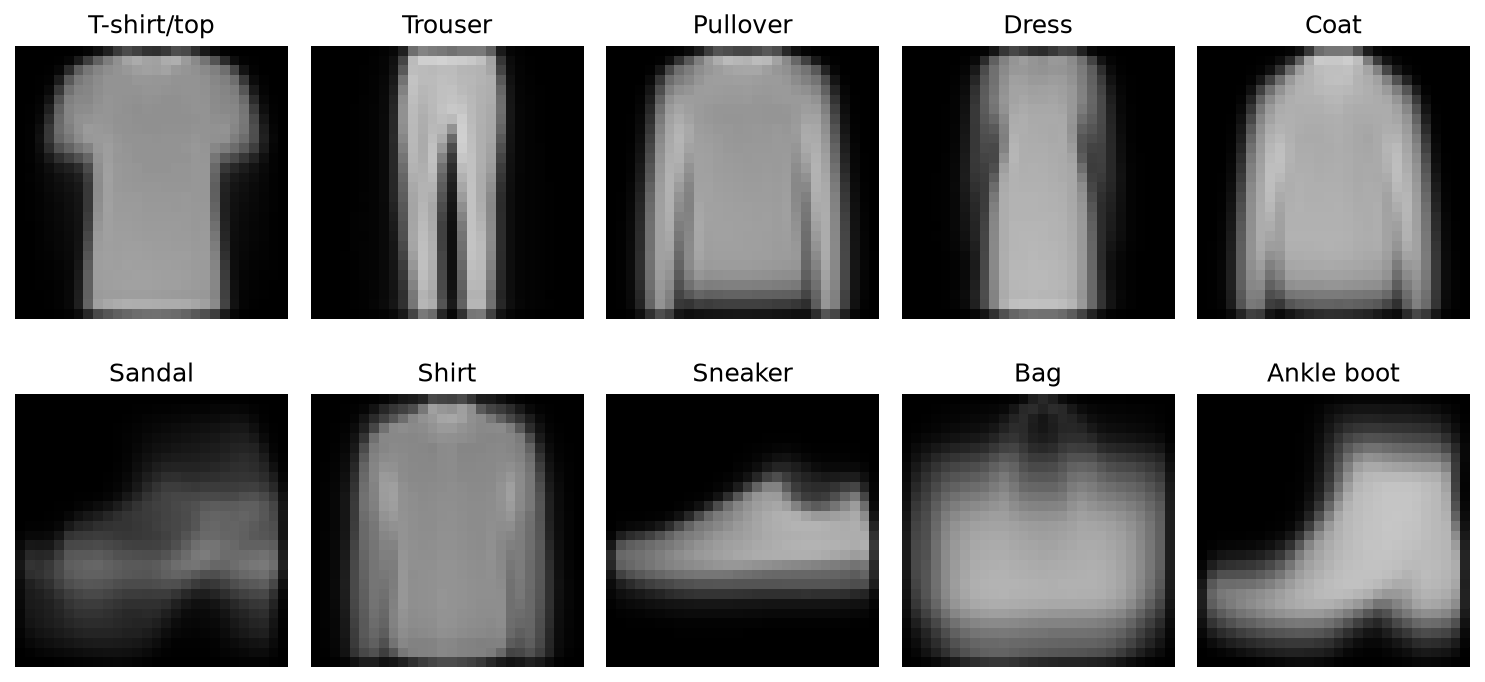

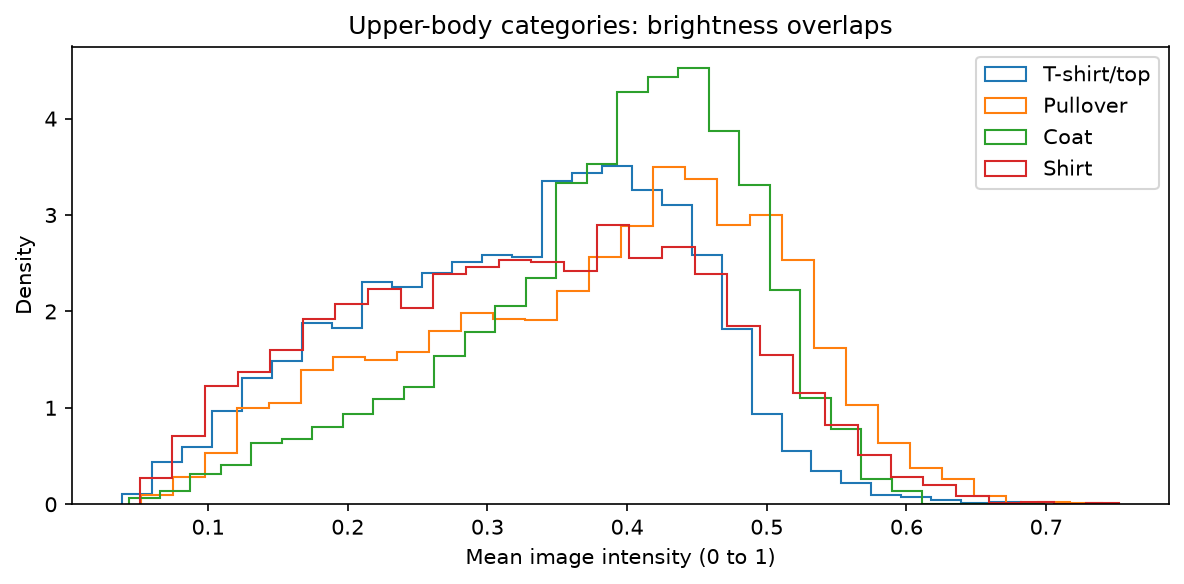

In [ ]:
display(Image(filename=str(ROOT / "reports/figures/training_samples.png")))
display(Image(filename=str(ROOT / "reports/figures/class_means.png")))
display(Image(filename=str(ROOT / "reports/figures/intensity_distribution.png")))

## 2. Feature engineering
Pixels become float32 values in [0,1], then flatten to 784 entries. Reshaping the vector recovers every pixel in the original image.

HOG measures edge directions and groups them into histograms within small cells. It normalizes overlapping blocks of cells, then joins the values into one vector. Nine bins with 7x7-pixel cells and 2x2-cell blocks give 324 values. The extra fine-HOG experiment uses 4x4 cells and 1,296 values. We keep image orientation fixed.

StandardScaler is fitted on training data only for Logistic Regression. Linear SVM uses the already normalized descriptors directly with solver tolerance 1e-3 and max_iter 2,000. k-NN, RF and RBF SVM also use the fixed pixel/HOG values directly.

pixels (3, 784) float32
hog (3, 324) float32
hog_fine (3, 1296) float32


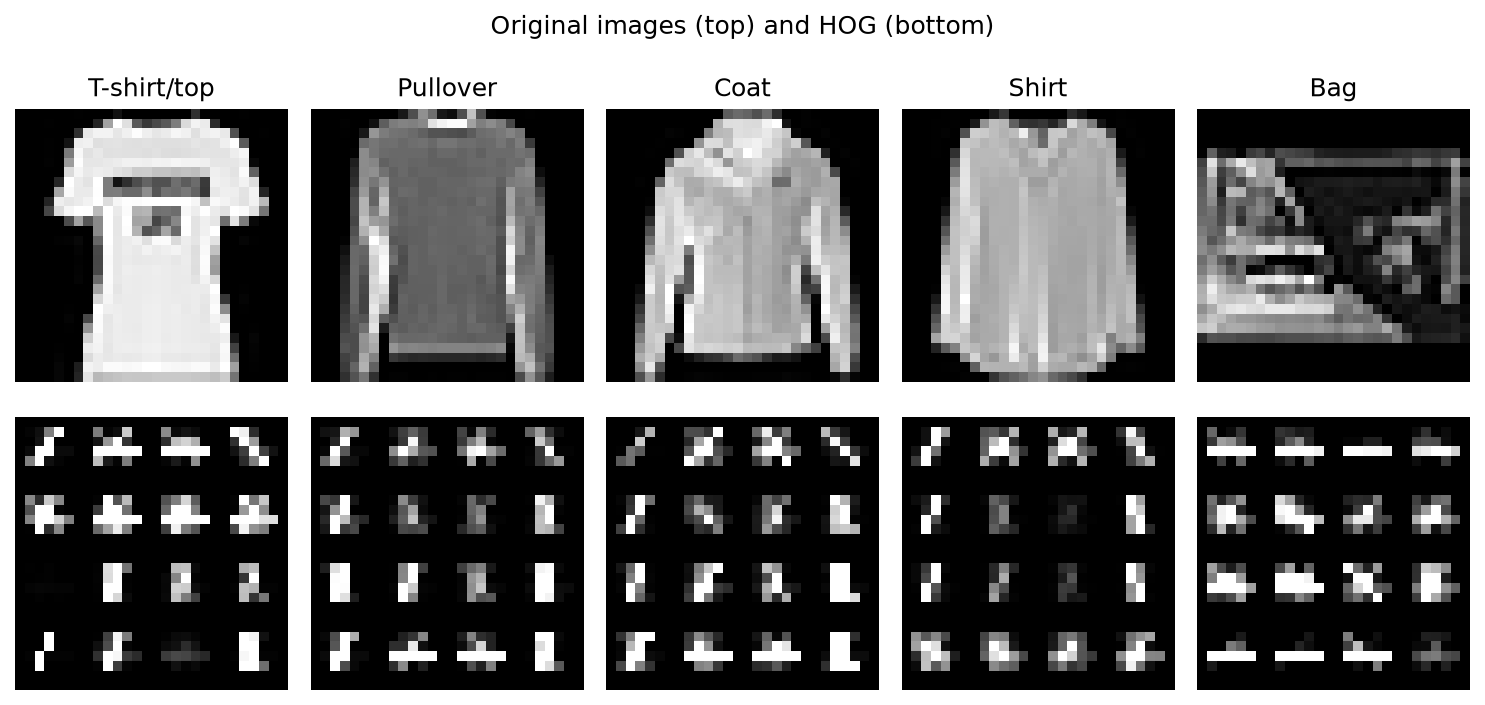

In [ ]:
sample = images[train_ids[:3]]
for representation in ("pixels", "hog", "hog_fine"):
    values = extract(sample, representation)
    print(representation, values.shape, values.dtype)
assert np.allclose(extract(sample, "pixels").reshape(3,28,28), sample / 255)
display(Image(filename=str(ROOT / "reports/figures/hog_visualization.png")))

## 3. Four classical decision rules
- Logistic Regression learns linear class scores using log loss and regularization.
- k-NN uses nearby training examples to vote, giving closer examples more weight.
- Random Forest combines randomized decision trees.
- Linear SVM learns class boundaries by balancing margins and training errors.

Eight required combinations = two representations x four classifiers. Each has two candidate settings. Additional RBF SVM trials test nonlinear boundaries on pixels, HOG and fine HOG. We keep these extra runs separate from the eight core comparisons. RBF uses exp(-gamma ||x-z||^2); C controls regularization.

The next cell displays the library model and its scaler. It loads the saved validation results without fitting a model.

In [ ]:
print(build("logistic_regression", {"C": 1.0}))
validation = pd.read_csv(ROOT / "reports/validation_results.csv")
display(validation[["name","feature_count","parameters","training_images","accuracy","macro_f1","fit_seconds"]])
frozen = json.loads((ROOT / "reports/frozen.json").read_text())
print("Selected before test evaluation:", frozen["selected"])
assert frozen["selected"] == validation.iloc[0]["name"]

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=2000))])


,name,feature_count,parameters,training_images,accuracy,macro_f1,fit_seconds
0,hog_fine_rbf_svm,1296,"{""C"": 3.0, ""gamma"": ""scale""}",48000,0.913583,0.913440,229.668698
1,pixels_rbf_svm,784,"{""C"": 10.0, ""gamma"": ""scale""}",48000,0.907750,0.907587,141.226295
2,pixels_random_forest,784,"{""n_estimators"": 400, ""max_depth"": null}",48000,0.886167,0.885012,67.485679
3,hog_rbf_svm,324,"{""C"": 3.0, ""gamma"": ""scale""}",48000,0.884750,0.884817,85.359877
4,pixels_knn,784,"{""n_neighbors"": 3}",48000,0.859167,0.859571,0.007001
5,pixels_logistic_regression,784,"{""C"": 0.1}",48000,0.859667,0.859077,16.950966
6,pixels_linear_svm,784,"{""C"": 0.1}",48000,0.858833,0.857138,33.654731
7,hog_logistic_regression,324,"{""C"": 0.1}",48000,0.855083,0.854904,4.378055
8,hog_linear_svm,324,"{""C"": 1.0}",48000,0.853167,0.852147,12.909098
9,hog_random_forest,324,"{""n_estimators"": 200, ""max_depth"": 25}",48000,0.850000,0.849472,51.822125


Selected before test evaluation: hog_fine_rbf_svm


## 4. Final test evaluation
Accuracy measures overall correctness. For each class, precision measures how many predicted positives are correct and recall measures how many true positives are recovered. F1 = 2TP/(2TP+FP+FN); macro F1 averages the ten class scores.

We compare test results for every retained model. Our selected model remains the one chosen using validation data.

,name,test_accuracy,test_macro_f1,feature_count,complexity_kind,complexity_count,model_bytes
0,hog_fine_rbf_svm,0.9087,0.908396,1296,support vectors,17835,55305234
1,pixels_rbf_svm,0.8973,0.897063,784,support vectors,15724,16318516
2,pixels_random_forest,0.8761,0.874729,784,tree nodes,3264176,73356923
3,hog_rbf_svm,0.8770,0.876905,324,support vectors,17835,19468113
4,pixels_knn,0.8509,0.851463,784,stored training images,48000,32613323
5,pixels_logistic_regression,0.8396,0.838975,784,linear coefficients and intercepts,7850,48051
6,pixels_linear_svm,0.8397,0.837303,784,linear coefficients and intercepts,7850,60979
7,hog_logistic_regression,0.8455,0.844993,324,linear coefficients and intercepts,3250,20702
8,hog_linear_svm,0.8401,0.838538,324,linear coefficients and intercepts,3250,25603
9,hog_random_forest,0.8459,0.845506,324,tree nodes,1948146,44269751


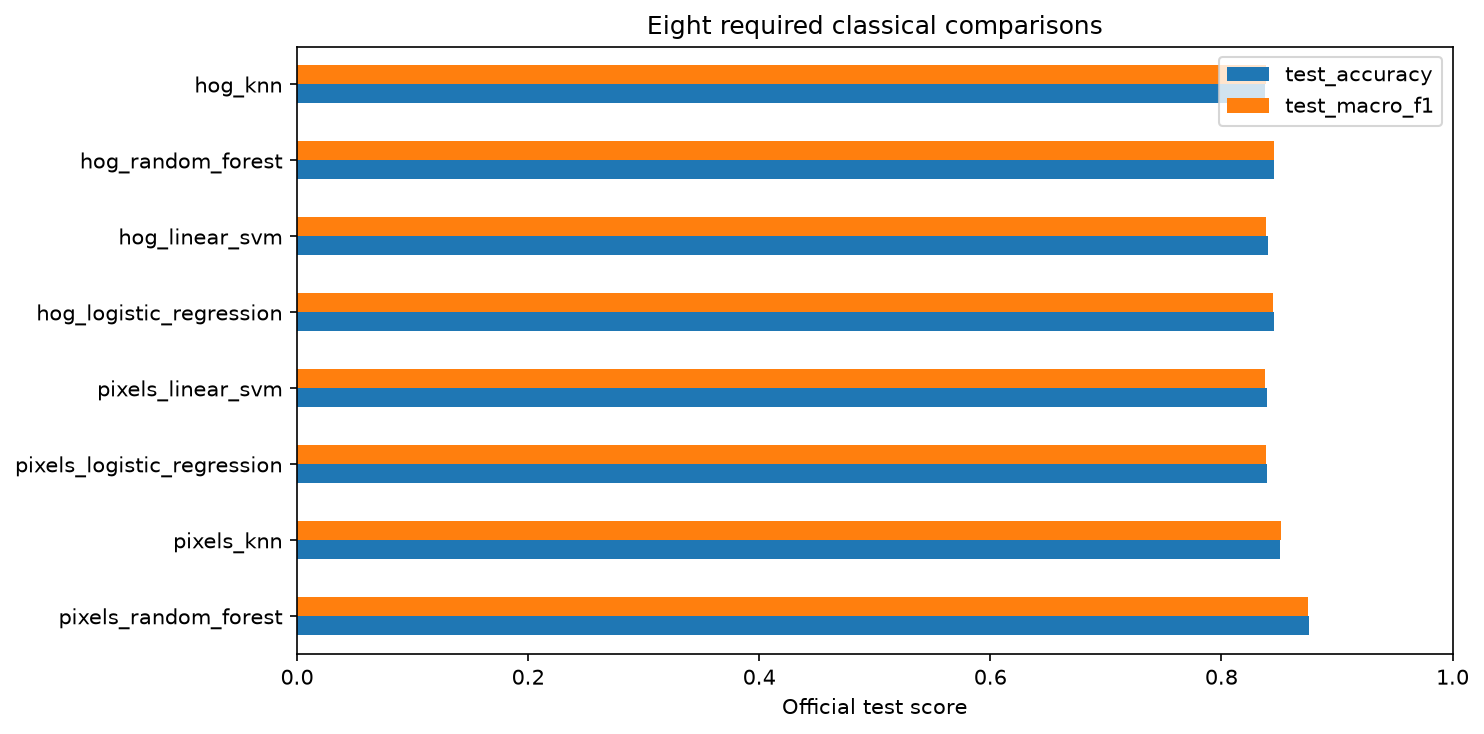

Validation-selected model test accuracy: 90.87%


In [ ]:
test = pd.read_csv(ROOT / "reports/test/results.csv")
display(test[["name","test_accuracy","test_macro_f1","feature_count","complexity_kind","complexity_count","model_bytes"]])
display(Image(filename=str(ROOT / "reports/figures/core_comparison.png")))
selected = frozen["selected"]
selected_row = test.set_index("name").loc[selected]
print(f"Validation-selected model test accuracy: {selected_row.test_accuracy:.2%}")

## 5. Shirts, T-shirts, pullovers, and coats
Confusion rows are true categories and columns are predictions. A Shirt predicted as Coat and a Coat predicted as Shirt count as different mistakes. We sample upper-body errors with a fixed seed for inspection. This sample does not represent all failures.

,category,precision,recall,f1-score,support
0,T-shirt/top,0.860721,0.859,0.859860,1000.0
1,Trouser,0.986882,0.978,0.982421,1000.0
2,Pullover,0.859422,0.862,0.860709,1000.0
3,Dress,0.903638,0.919,0.911254,1000.0
4,Coat,0.841546,0.871,0.856020,1000.0
5,Sandal,0.978745,0.967,0.972837,1000.0
6,Shirt,0.750789,0.714,0.731932,1000.0
7,Sneaker,0.942607,0.969,0.955621,1000.0
8,Bag,0.982072,0.986,0.984032,1000.0
9,Ankle boot,0.976650,0.962,0.969270,1000.0


,true,predicted,count,rate_within_true_class
0,Shirt,T-shirt/top,116,0.116
1,T-shirt/top,Shirt,102,0.102
2,Shirt,Coat,66,0.066
3,Shirt,Pullover,64,0.064
4,Pullover,Coat,58,0.058
5,Pullover,Shirt,57,0.057
6,Coat,Pullover,53,0.053
7,Coat,Shirt,43,0.043
8,T-shirt/top,Pullover,16,0.016
9,Pullover,T-shirt/top,11,0.011


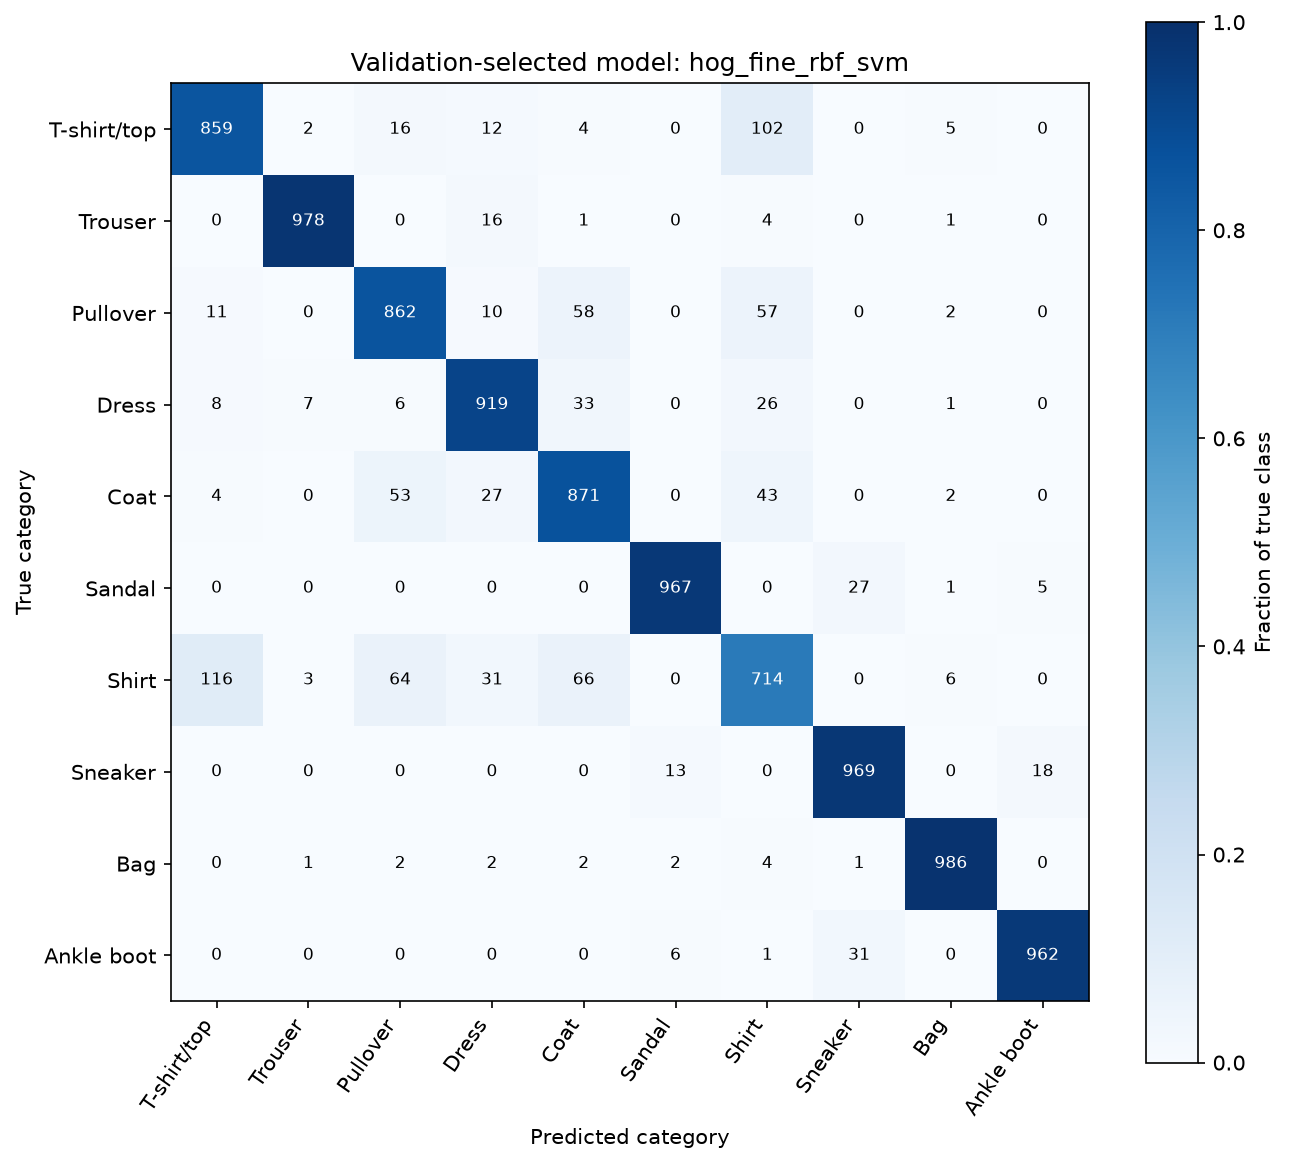

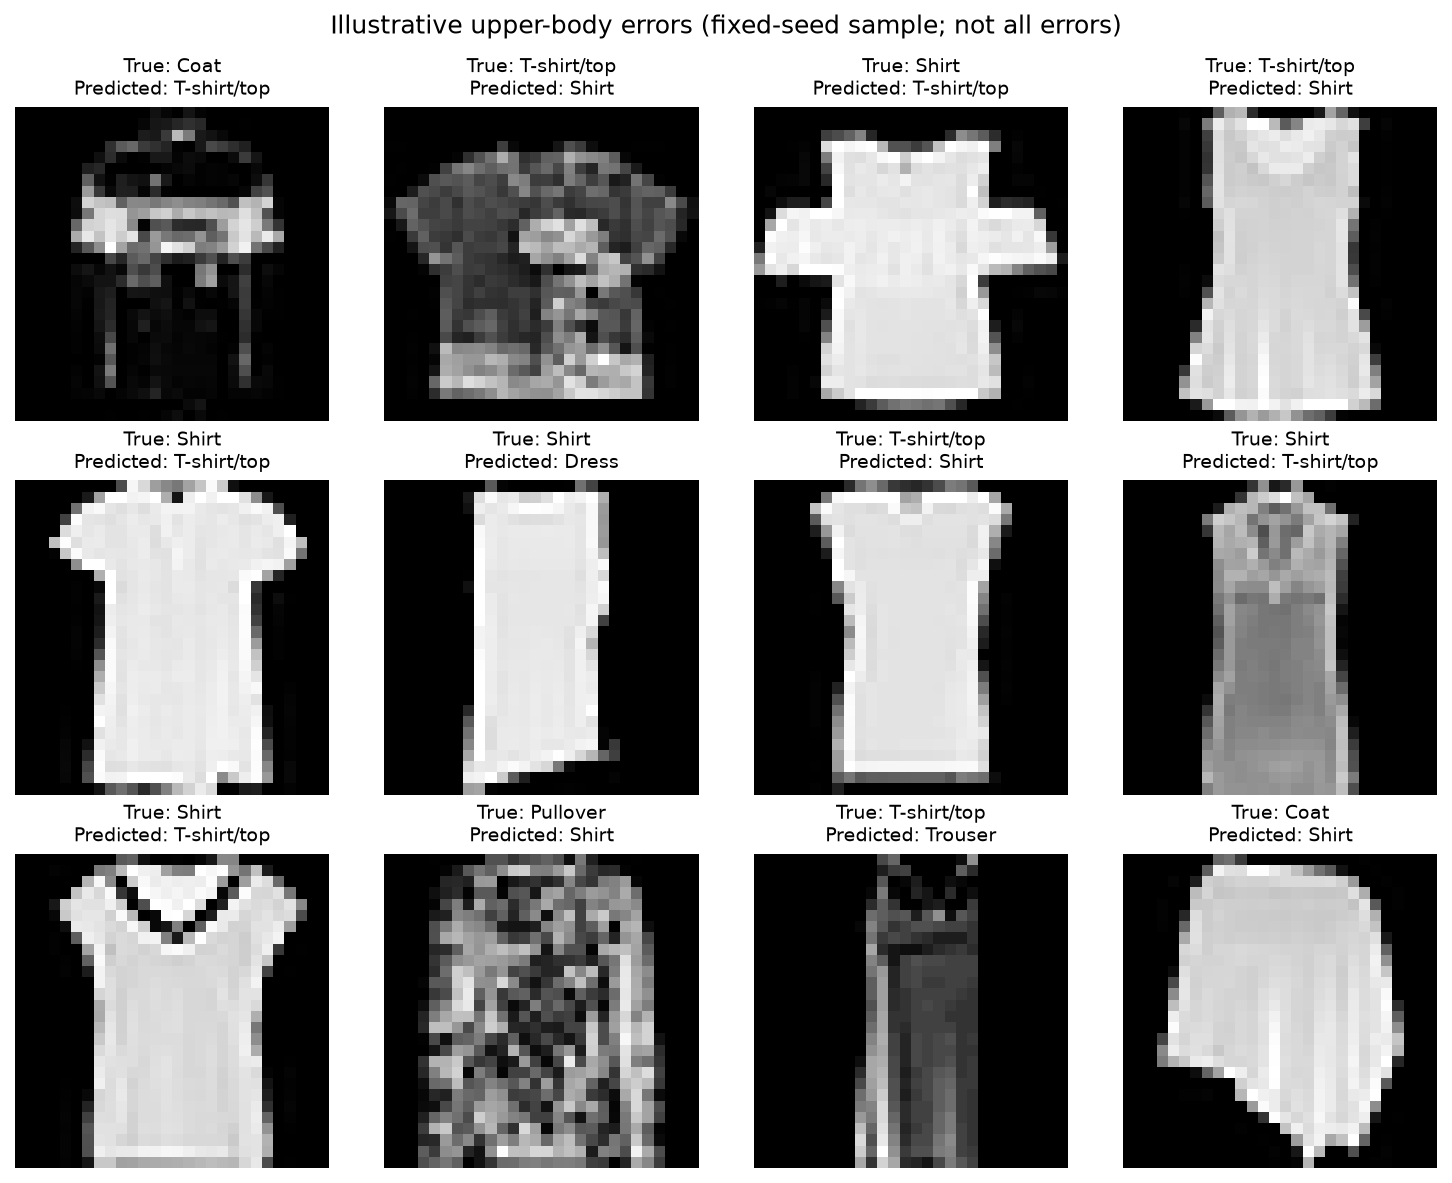

In [ ]:
per_class = pd.read_csv(ROOT / "reports/test/per_class.csv")
display(per_class[per_class.name == selected].drop(columns="name"))
display(pd.read_csv(ROOT / "reports/test/upper_body_confusions.csv"))
display(Image(filename=str(ROOT / "reports/figures/selected_confusion.png")))
display(Image(filename=str(ROOT / "reports/figures/error_examples.png")))

## 6. Accuracy versus computational cost
Timings include descriptor extraction and learned pipeline scaling on the same CPU. Single-image latency is separate from throughput over batches of 128. Timing excludes file decoding and model loading. Model capacity takes different forms: forests store nodes, k-NN stores images, and kernel SVMs store support vectors. These counts cannot be treated as equivalent parameter counts.

,name,fit_seconds,single_ms_median,single_ms_p95,batch_ms_per_image,batch_images_per_second,model_bytes
0,hog_fine_rbf_svm,229.668698,10.168917,15.732137,16.810477,5.948671e+01,55305234
1,pixels_rbf_svm,141.226295,3.843250,3.916573,3.774874,2.649095e+02,16318516
2,pixels_random_forest,67.485679,25.327896,25.803605,0.192157,5.204083e+03,73356923
3,hog_rbf_svm,85.359877,2.191750,2.316994,2.083455,4.799720e+02,19468113
4,pixels_knn,0.007001,8.414355,8.746469,0.281835,3.548178e+03,32613323
5,pixels_logistic_regression,16.950966,0.113312,0.130216,0.001721,5.809517e+05,48051
6,pixels_linear_svm,33.654731,0.058708,0.064486,0.000970,1.030959e+06,60979
7,hog_logistic_regression,4.378055,0.179708,0.194729,0.077522,1.289964e+04,20702
8,hog_linear_svm,12.909098,0.127792,0.145890,0.077339,1.293003e+04,25603
9,hog_random_forest,51.822125,13.098959,13.301863,0.177901,5.621103e+03,44269751


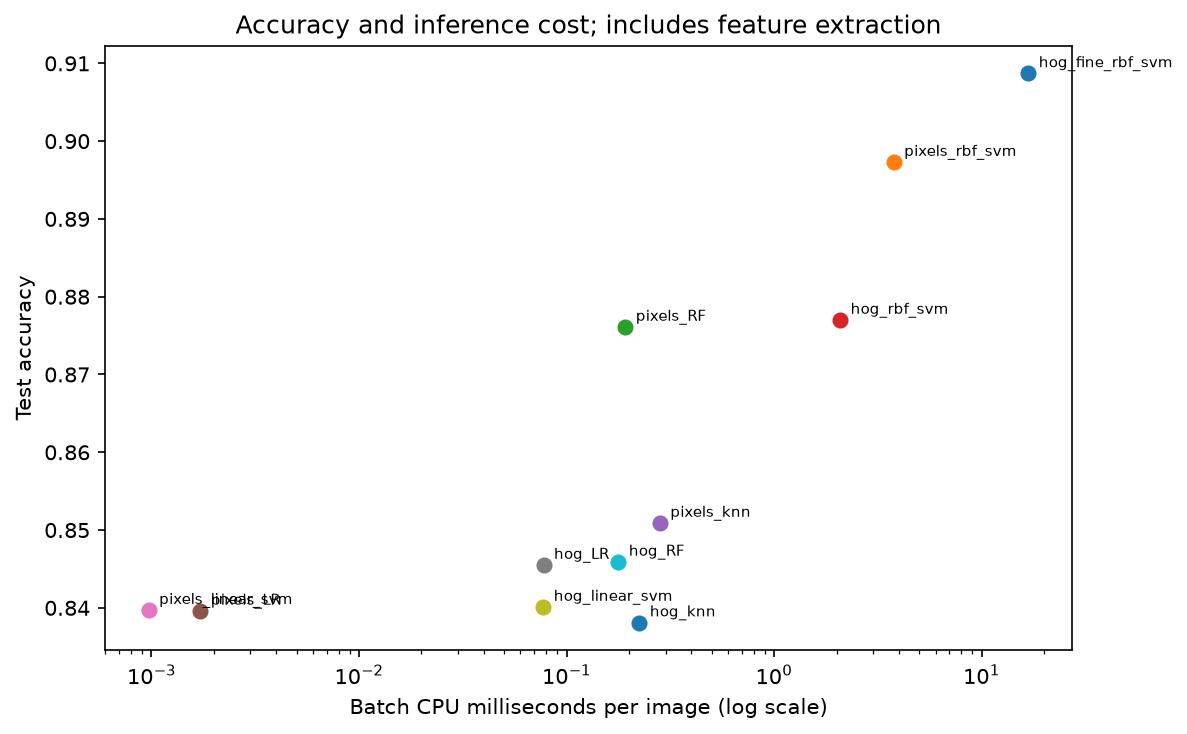

In [ ]:
display(test[["name","fit_seconds","single_ms_median","single_ms_p95","batch_ms_per_image","batch_images_per_second","model_bytes"]])
display(Image(filename=str(ROOT / "reports/figures/accuracy_cost.png")))

## 7. Reusable prediction
This example loads a saved model and predicts one training image. It demonstrates prediction only and provides no additional accuracy estimate. For a command-line demonstration use `uv run python3 -m src.inventory_tagging.cli predict path/to/image.png` with a 28x28 grayscale image on a dark background. Arbitrary phone-photo performance has not been measured.

In [ ]:
import joblib
from src.inventory_tagging.data import sha256
# A new clone builds into runs/reproduction; the original reports stay separate.
demo_root = ROOT if (ROOT / "models" / f"{selected}.joblib").exists() else ROOT / "runs/reproduction"
demo_manifest = demo_root / "reports/frozen.json"
if demo_manifest.exists():
    demo_frozen = json.loads(demo_manifest.read_text())
    record = next(m for m in demo_frozen["models"] if m["name"] == demo_frozen["selected"])
    model_path = demo_root / "models" / f"{record['name']}.joblib"
else:
    model_path = None
if model_path is not None and model_path.exists():
    if sha256(model_path) != record["model_sha256"]:
        raise ValueError("The model does not match this run's saved record.")
    if sha256(ROOT / "data/split.npz") != record["split_sha256"]:
        raise ValueError("The demo's training images use a different split.")
    model = joblib.load(model_path)
    index = int(train_ids[0])
    prediction = int(model.predict(extract(images[index:index+1], record["representation"]))[0])
    print("Model folder for this demonstration:", demo_root)
    print("Known category:", CLASSES[int(labels[index])])
    print("Predicted category:", CLASSES[prediction])
else:
    print("Saved results are available. To enable prediction, run: bash scripts/build_models.sh")

Demonstration true category: Shirt
Predicted category: Shirt


## 8. Conclusions, limitations, and viva
Read `reports/phase1_findings.md` for result-specific conclusions, `docs/literature_review.md` for primary sources, and `docs/viva_guide.md` for explanations. The findings apply to one split and a limited search. Full catalogue photos, unseen classes, near-duplicates and calibration need separate evaluation.

The reference is acknowledged in `docs/ATTRIBUTION.md`. All result tables use our new experiment with 48k training images. Phase 2 will use this same split for a small CNN with pooling, dropout and early stopping, then compare errors and compute cost.